Having extracted the model data fields, plot a temperature map at a depth that just makes it over the Greenland-Scotland ridge, and add markers where each the profiles are extracted for the T-S plot.

In [20]:
import pickle

# Load the saved late profile dataoutput_file = 'cmip6_profiles_4locations.pkl'
with open('/Users/jaimepalter/cmip6_profiles_4locations.pkl', 'rb') as f:
   profiles = pickle.load(f)

print("✓All Profiles loaded from cmip6_profiles_4locations.pkl")

✓All Profiles loaded from cmip6_profiles_4locations.pkl


In [21]:
successful_models = sorted(profiles.keys())

print("successful_models = [")
for model in successful_models:
    print(f"    '{model}',")
print("]")

successful_models = [
    'ACCESS-CM2',
    'ACCESS-ESM1-5',
    'BCC-CSM2-MR',
    'BCC-ESM1',
    'CAMS-CSM1-0',
    'CAS-ESM2-0',
    'CMCC-CM2-SR5',
    'CMCC-ESM2',
    'CanESM5',
    'EC-Earth3',
    'EC-Earth3-AerChem',
    'EC-Earth3-CC',
    'EC-Earth3-Veg-LR',
    'FGOALS-f3-L',
    'FGOALS-g3',
    'GFDL-CM4',
    'GFDL-ESM4',
    'GISS-E2-1-G',
    'GISS-E2-1-G-CC',
    'IPSL-CM5A2-INCA',
    'IPSL-CM6A-LR',
    'IPSL-CM6A-LR-INCA',
    'MPI-ESM-1-2-HAM',
    'MPI-ESM1-2-HR',
    'MPI-ESM1-2-LR',
    'MRI-ESM2-0',
    'NESM3',
]


In [22]:
import intake
import xarray as xr
from xmip.preprocessing import combined_preprocessing
import pickle
from tqdm import tqdm

# Load catalog
url = "https://storage.googleapis.com/cmip6/pangeo-cmip6.json"
col = intake.open_esm_datastore(url)

query = dict(
    experiment_id=['historical'],
    table_id='Omon',
    member_id='r1i1p1f1',
    variable_id=['thetao', 'so'],
    grid_label='gn',
)

cat = col.search(**query)


# Load only the successful models
z_kwargs = {
    'consolidated': True,
    'decode_times': False,
}

dset_dict = {}

for model in tqdm(successful_models, desc="Loading models", unit="model"):
    try:
        cat_model = cat.search(source_id=model)
        
        from dask import config
        with config.set(**{'array.slicing.split_large_chunks': True}):
            dset_model = cat_model.to_dataset_dict(
                zarr_kwargs=z_kwargs,
                preprocess=combined_preprocessing,
                progressbar=False,
                skip_on_error=True
            )
        
        dset_dict.update(dset_model)
        tqdm.write(f"✓ {model}")
        
    except Exception as e:
        tqdm.write(f"❌ {model}: {e}")
        continue

# Save for future use
with open('dset_dict_fresh.pkl', 'wb') as f:
    pickle.dump(dset_dict, f)

print(f"\nLoaded {len(dset_dict)} datasets")
print("Saved to dset_dict_fresh.pkl")

Loading models:   0%|                                               | 0/27 [00:00<?, ?model/s]Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Defau

✓ ACCESS-CM2


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

✓ ACCESS-ESM1-5


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

✓ BCC-CSM2-MR


... (44 outputs left out)

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

✓ MRI-ESM2-0


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

✓ NESM3

Loaded 27 datasets
Saved to dset_dict_fresh.pkl


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import time
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec




# Set up subplots
models_to_plot = {k: v for k, v in dset_dict.items() 
                  if k.split(".")[2] in successful_models}

print(f"Filtering to {len(models_to_plot)} successful models\n")

# ===== VALIDATION PASS: Filter out bad models =====
valid_models = {}

for key, ds in models_to_plot.items():
    model_name = key.split(".")[2]
    
    # Check 1: Has required variable?
    if 'thetao' not in ds.data_vars or 'so' not in ds.data_vars:
        print(f"❌ SKIPPED {model_name}: Missing 'thetao' or 'so'")
        continue
    
    # Check 2: Has lev coordinate?
    if 'lev' not in ds.coords:
        print(f"❌ SKIPPED {model_name}: No 'lev' coordinate")
        continue
    
    # Check 3: Can we get a valid depth slice?
    try:
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # Check 4: Does the depth slice have valid data?
        n_valid = (~np.isnan(temp_800m.values)).sum()
        if n_valid == 0:
            print(f"❌ SKIPPED {model_name}: All NaN at depth slice")
            continue
        
        # If we got here, this model is valid!
        valid_models[key] = ds
        print(f"✓ {model_name}: Valid ({n_valid} non-NaN points)")
        
    except Exception as e:
        print(f"❌ SKIPPED {model_name}: {type(e).__name__}: {e}")
        continue

print(f"\n{'='*60}")
print(f"Valid models: {len(valid_models)} / {len(models_to_plot)}")
print(f"{'='*60}\n")

# ===== FIRST PASS: Find global vmin/vmax across all models =====
print("Finding global temperature range...")
all_temps = []

for key, ds in valid_models.items():
    ds_period = ds.isel(time=-1)
    thetao = ds_period['thetao']
    depth_coord = ds['lev'].values
    target_depth = 800
    depth_idx = np.argmin(np.abs(depth_coord - target_depth))
    temp_800m = thetao.isel(lev=depth_idx).squeeze()
    all_temps.append(temp_800m.values[~np.isnan(temp_800m.values)])

all_temps = np.concatenate(all_temps)
vmin, vmax = np.nanpercentile(all_temps, [2, 98])  # Use 2nd and 98th percentiles to avoid extremes
print(f"Global temp range: {vmin:.2f} to {vmax:.2f} °C\n")



Filtering to 27 successful models



Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


✓ ACCESS-CM2: Valid (57288 non-NaN points)


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


✓ ACCESS-ESM1-5: Valid (57288 non-NaN points)


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

... (43 outputs left out)

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

✓ NESM3: Valid (55227 non-NaN points)

Valid models: 22 / 27

Finding global temperature range...


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

Global temp range: 0.20 to 11.91 °C



Figure size: figsize=(16, 30)
Processing ACCESS-CM2...


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

  ✓ Successfully plotted in 28.01s

Processing ACCESS-ESM1-5...


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

  ✓ Successfully plotted in 27.42s

Processing BCC-CSM2-MR...


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

... (35 outputs left out)

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

  ✓ Successfully plotted in 25.80s

Processing NESM3...


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

  ✓ Successfully plotted in 93.25s



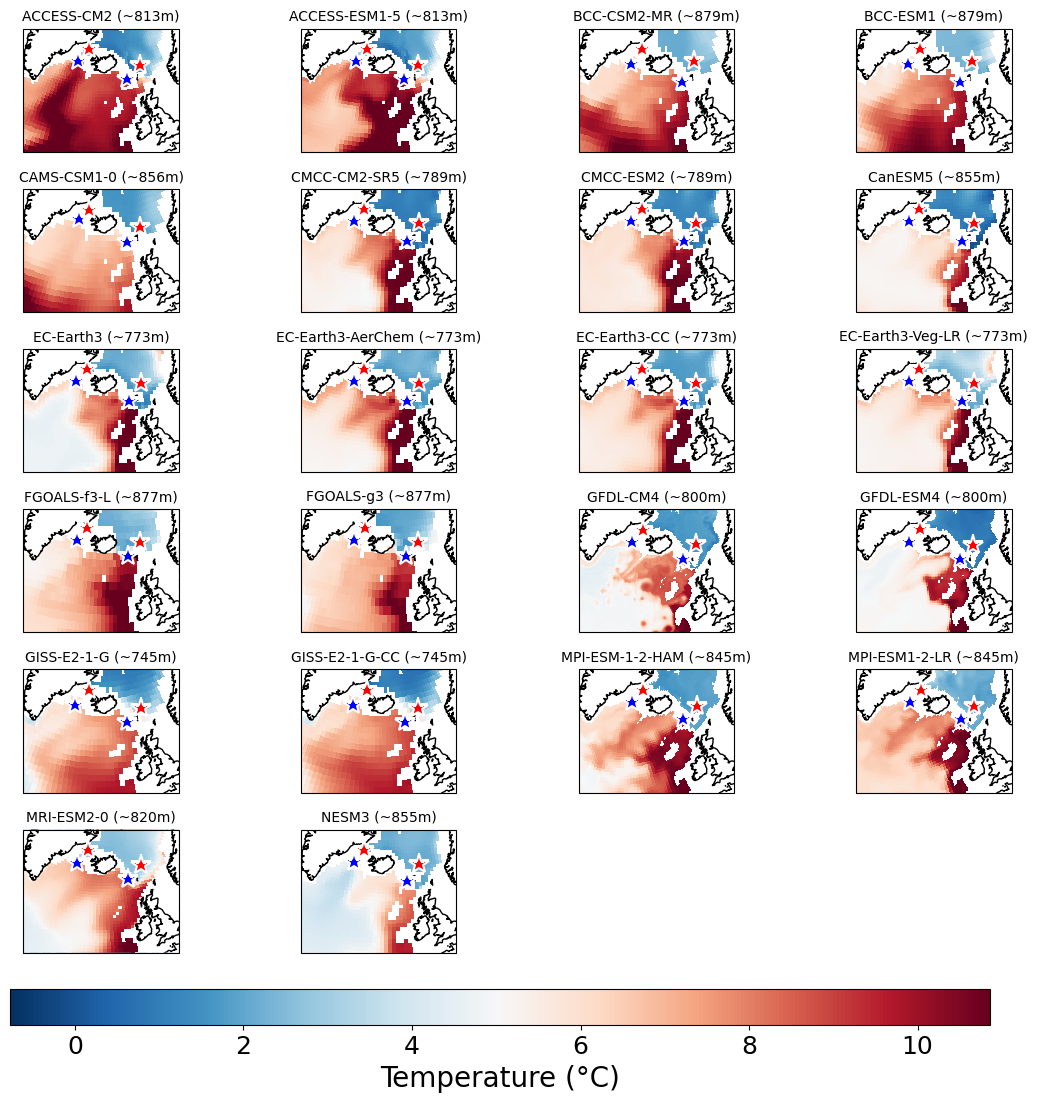

In [57]:
# ===== NOW CREATE SUBPLOTS ONLY FOR VALID MODELS =====
n_models = len(valid_models)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols

#fig = plt.figure(figsize=(16, n_rows * 5))
fig = plt.figure(figsize=(14, 12))
gs = gridspec.GridSpec(n_rows, n_cols, hspace=0.3, wspace=0.1)

print(f"Figure size: figsize=(16, {n_rows * 5})")
axes = []
for i in range(n_rows * n_cols):
    proj = ccrs.NorthPolarStereo(central_longitude=340)
    #ax = fig.add_subplot(n_rows, n_cols, i+1, projection=proj)
    ax = fig.add_subplot(gs[i], projection=proj)
    fig.subplots_adjust(hspace=0.2, wspace=0.2)  # Adjust these values
    axes.append(ax)
axes = np.array(axes)

locations = {
    'SPSide_DS': {'lat': 65.0, 'lon': 330.0},
    'SPSide_FSC': {'lat': 62, 'lon': 350.0},
    'DenStrait': {'lat': 67.5, 'lon': 334},
    'FSChannel': {'lat': 64, 'lon': 356}
}

# Create colormap for all plots
cmap = plt.cm.RdBu_r
norm = plt.Normalize(vmin=vmin, vmax=vmax)

plot_idx = 0
for key, ds in valid_models.items():
    tic = time.perf_counter()
    model_name = key.split(".")[2]
    print(f"Processing {model_name}...")
    
    try:
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        
        # Get depth coordinate
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        # Select depth level
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # Get lat/lon arrays
        lat_2d = ds['lat'].values
        lon_2d = ds['lon'].values
        
        # Ensure lat/lon shape matches data dimensions
        if lat_2d.shape != temp_800m.shape:
            lat_2d = lat_2d.T
            lon_2d = lon_2d.T
        
        # Use the Cartopy axis
        ax = axes[plot_idx]
        
        # Plot with shared norm (NO individual colorbar)
        cmap.set_bad('white')  # or 'lightgray', 'none', etc.
        im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, 
                           cmap=cmap, norm=norm, shading='auto',
                           transform=ccrs.PlateCarree())
        ax.coastlines()
        
        # Add location markers
        for loc_name, coords in list(locations.items())[0:2]:
            lat_mask = np.abs(lat_2d - coords['lat']) <= 3
            lon_mask = np.abs(lon_2d - coords['lon']) <= 3
            search_region = lat_mask & lon_mask
            
            if np.any(search_region):
                lat_search = lat_2d[search_region]
                lon_search = lon_2d[search_region]
                dist_search = np.sqrt((lat_search - coords['lat'])**2 + 
                                     (lon_search - coords['lon'])**2)
                
                search_indices = np.where(search_region)
                nearest_idx = np.argmin(dist_search)
                row_id = search_indices[0][nearest_idx]
                col_id = search_indices[1][nearest_idx]
                
                nearest_lat = lat_2d[row_id, col_id]
                nearest_lon = lon_2d[row_id, col_id]
                
                ax.plot(nearest_lon, nearest_lat, 'b*', markersize=15, 
                       markeredgecolor='white', markeredgewidth=1.5, label=loc_name, 
                       transform=ccrs.PlateCarree(), zorder=1000)
                
        
        ax.set_title(f'{model_name} (~{round(actual_depth)}m)', fontsize=10)
        ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())
        
        #if plot_idx == 0:
            #ax.legend(fontsize=10, loc='upper left')
        
        toc = time.perf_counter()
        print(f"  ✓ Successfully plotted in {toc - tic:.2f}s\n")
        
        plot_idx += 1
        
    except Exception as e:
        print(f"  ❌ ERROR during plotting: {type(e).__name__}: {e}\n")

    for loc_name, coords in list(locations.items())[2:4]:
        lat_mask = np.abs(lat_2d - coords['lat']) <= 3
        lon_mask = np.abs(lon_2d - coords['lon']) <= 3
        search_region = lat_mask & lon_mask
            
        if np.any(search_region):
            lat_search = lat_2d[search_region]
            lon_search = lon_2d[search_region]
            dist_search = np.sqrt((lat_search - coords['lat'])**2 + 
                                     (lon_search - coords['lon'])**2)
                
            search_indices = np.where(search_region)
            nearest_idx = np.argmin(dist_search)
            row_id = search_indices[0][nearest_idx]
            col_id = search_indices[1][nearest_idx]
                
            nearest_lat = lat_2d[row_id, col_id]
            nearest_lon = lon_2d[row_id, col_id]
                
            ax.plot(nearest_lon, nearest_lat, 'r*', markersize=15, 
                    markeredgecolor='white', markeredgewidth=1.5, label=loc_name, 
                    transform=ccrs.PlateCarree(), zorder=1000)
# Hide unused subplots
for idx in range(plot_idx, len(axes)):
    axes[idx].axis('off')

# ===== ADD SINGLE COLORBAR =====
# cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]

# Create colorbar axis (spans all columns, single row below)
cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.03])  # [left, bottom, width, height]

sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)

#sm.set_array([])
#cbar = fig.colorbar(sm, cax=cbar_ax)
#cbar.ax.tick_params(labelsize=18)
#fig.canvas.draw()

# Then your colorbar code:
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.ax.tick_params(labelsize=18)
cbar.set_label('Your Label', fontsize=18)  # Add label if needed
fig.canvas.draw()




cbar.set_label('Temperature (°C)', fontsize=20)

plt.subplots_adjust(right=0.9)  # Make room for colorbar

from pathlib import Path

save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/Temperature_12_2014_800.png')
plt.savefig(save_path, dpi=300)#, bbox_inches='tight')
#plt.show()

In [20]:
# Create colorbar axis below plots
cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.03])  # [left, bottom, width, height]

# Create the colorbar
sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.ax.tick_params(labelsize=18)
cbar.set_label('Your Label', fontsize=18)
fig.canvas.draw()

In [30]:
from pathlib import Path

save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/Temperature_12_2014_800.png')
fig.savefig(save_path, dpi=300, bbox_inches='tight')


In [33]:
import pickle
import numpy as np



# Load profiles
output_file = '/Users/jaimepalter/cmip6_profiles_4locations.pkl'
with open(output_file, 'rb') as f:
    profiles = pickle.load(f)

# Models to check
models_to_check = ['FGOALS-f3-L', 'FGOALS-g3', 'MRI-ESM2-0']

print("Temperature range at 800m depth (last time step):\n")

for model_name in models_to_check:
    if model_name not in profiles:
        print(f"❌ {model_name} not found")
        continue
    
    try:
        # Get one location's data
        loc_data = profiles[model_name]['SPSide_DS']['period2_1995-2014']
        
        depth = loc_data['depth']
        temp = loc_data['thetao']
        
        # Find closest to 800m
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth - target_depth))
        actual_depth = depth[depth_idx]
        
        temp_at_depth = temp[depth_idx]
        
        print(f"{model_name}:")
        print(f"  Depth: {actual_depth:.0f}m (target: {target_depth}m)")
        print(f"  Temperature: {temp_at_depth:.2f}°C")
        print(f"  Full profile at 800m: min={np.nanmin(temp):.2f}, max={np.nanmax(temp):.2f}")
        print(f"  NaN count: {np.sum(np.isnan(temp))}/{len(temp)}")
        print()
        
    except Exception as e:
        print(f"❌ {model_name}: {type(e).__name__}: {e}\n")

# Models to check
models_to_check = ['FGOALS-f3-L', 'FGOALS-g3', 'MRI-ESM2-0']

print("Temperature range at 800m depth (last time step):\n")

for model_name in models_to_check:

    
    try:
        # Get one location's data
        loc_data = profiles[model_name]['SPSide_DS']['period2_1995-2014']
        
        depth = loc_data['depth']
        temp = loc_data['thetao']
        
        # Find closest to 800m
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth - target_depth))
        actual_depth = depth[depth_idx]
        
        temp_at_depth = temp[depth_idx]
        
        print(f"{model_name}:")
        print(f"  Depth: {actual_depth:.0f}m (target: {target_depth}m)")
        print(f"  Temperature: {temp_at_depth:.2f}°C")
        print(f"  Full profile at 800m: min={np.nanmin(temp):.2f}, max={np.nanmax(temp):.2f}")
        print(f"  NaN count: {np.sum(np.isnan(temp))}/{len(temp)}")
        print()
        
    except Exception as e:
        print(f"❌ {model_name}: {type(e).__name__}: {e}\n")

Temperature range at 800m depth (last time step):

FGOALS-f3-L:
  Depth: 877m (target: 800m)
  Temperature: nan°C
  Full profile at 800m: min=nan, max=nan
  NaN count: 30/30

FGOALS-g3:
  Depth: 877m (target: 800m)
  Temperature: 6.36°C
  Full profile at 800m: min=6.36, max=7.25
  NaN count: 5/30

MRI-ESM2-0:
  Depth: 820m (target: 800m)
  Temperature: 15.06°C
  Full profile at 800m: min=14.49, max=20.29
  NaN count: 11/61

Temperature range at 800m depth (last time step):

FGOALS-f3-L:
  Depth: 877m (target: 800m)
  Temperature: nan°C
  Full profile at 800m: min=nan, max=nan
  NaN count: 30/30

FGOALS-g3:
  Depth: 877m (target: 800m)
  Temperature: 6.36°C
  Full profile at 800m: min=6.36, max=7.25
  NaN count: 5/30

MRI-ESM2-0:
  Depth: 820m (target: 800m)
  Temperature: 15.06°C
  Full profile at 800m: min=14.49, max=20.29
  NaN count: 11/61



/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_8162/1677895916.py:38: RuntimeWarning: All-NaN slice encountered
  print(f"  Full profile at 800m: min={np.nanmin(temp):.2f}, max={np.nanmax(temp):.2f}")
/var/folders/h1/j3p_b5ts7314ws9g_tynb4g80000gn/T/ipykernel_8162/1677895916.py:70: RuntimeWarning: All-NaN slice encountered
  print(f"  Full profile at 800m: min={np.nanmin(temp):.2f}, max={np.nanmax(temp):.2f}")


DIAGNOSTIC: Temperature ranges at 800m for problematic models



Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

FGOALS-f3-L:
  Depth: 877m (target: 800m)
  Temp range: -0.56 to 19.46°C
  Temp mean: 4.47°C
  Valid points: 47305



Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

FGOALS-g3:
  Depth: 877m (target: 800m)
  Temp range: -1.74 to 16.94°C
  Temp mean: 3.11°C
  Valid points: 47305



Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

... (15 outputs left out)

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


  Valid points: 78801


Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more 

  Plot time: 38.48s



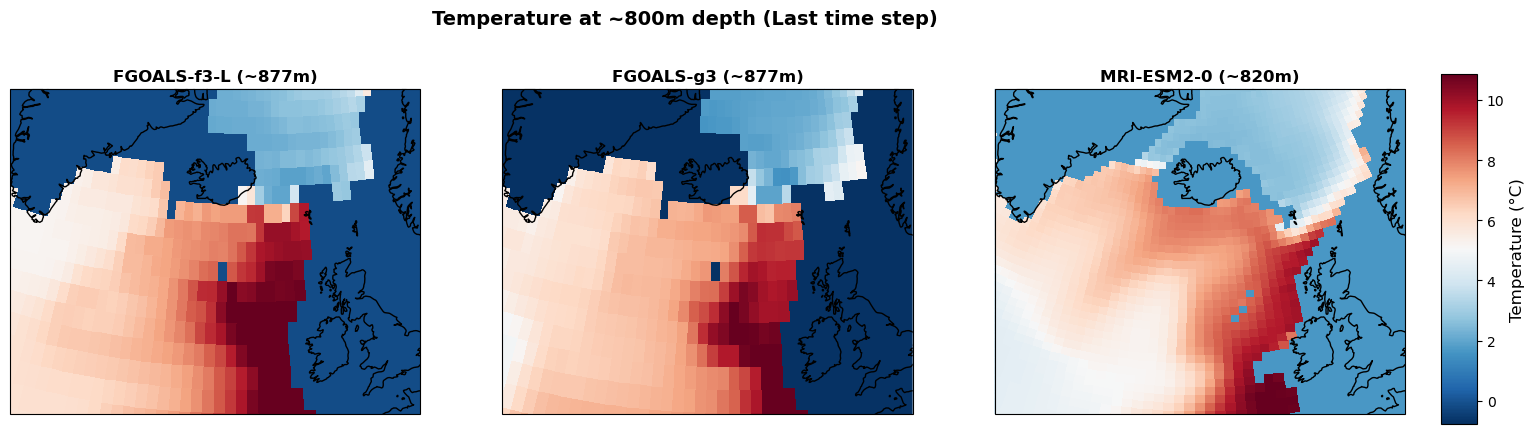


Diagnostic complete. Check the printed ranges above.


In [34]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import time
from matplotlib.cm import ScalarMappable

# Load dset_dict
with open('dset_dict_fresh.pkl', 'rb') as f:
    dset_dict = pickle.load(f)

# Models to check
models_to_check = ['FGOALS-f3-L', 'FGOALS-g3', 'MRI-ESM2-0']

print("="*70)
print("DIAGNOSTIC: Temperature ranges at 800m for problematic models")
print("="*70 + "\n")

# First pass: collect temperature ranges
temp_ranges = {}
all_temps = []

for key, ds in dset_dict.items():
    model_name = key.split(".")[2]
    
    if model_name not in models_to_check:
        continue
    
    try:
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        
        # Get depth coordinate
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        # Select depth level
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # Get stats
        temp_min = float(np.nanmin(temp_800m.values))
        temp_max = float(np.nanmax(temp_800m.values))
        temp_mean = float(np.nanmean(temp_800m.values))
        n_valid = np.sum(~np.isnan(temp_800m.values))
        
        temp_ranges[model_name] = {
            'min': temp_min,
            'max': temp_max,
            'mean': temp_mean,
            'n_valid': n_valid,
            'actual_depth': actual_depth
        }
        
        all_temps.append(temp_800m.values[~np.isnan(temp_800m.values)])
        
        print(f"{model_name}:")
        print(f"  Depth: {actual_depth:.0f}m (target: {target_depth}m)")
        print(f"  Temp range: {temp_min:.2f} to {temp_max:.2f}°C")
        print(f"  Temp mean: {temp_mean:.2f}°C")
        print(f"  Valid points: {n_valid}")
        print()
        
    except Exception as e:
        print(f"❌ {model_name}: {type(e).__name__}: {e}\n")

# Determine global colorscale
if all_temps:
    all_temps = np.concatenate(all_temps)
    vmin, vmax = np.nanpercentile(all_temps, [2, 98])
    print(f"\nGlobal temp range (2-98 percentile): {vmin:.2f} to {vmax:.2f}°C")
    print(f"All temps range: {np.nanmin(all_temps):.2f} to {np.nanmax(all_temps):.2f}°C\n")

# Now plot
print("="*70)
print("PLOTTING")
print("="*70 + "\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={'projection': ccrs.NorthPolarStereo(central_longitude=340)})
axes = axes.flatten()

cmap = plt.cm.RdBu_r
norm = plt.Normalize(vmin=vmin, vmax=vmax)

plot_idx = 0
for key, ds in dset_dict.items():
    model_name = key.split(".")[2]
    
    if model_name not in models_to_check:
        continue
    
    tic = time.perf_counter()
    
    try:
        ds_period = ds.isel(time=-1)
        thetao = ds_period['thetao']
        
        # Get depth coordinate
        depth_coord = ds['lev'].values
        target_depth = 800
        depth_idx = np.argmin(np.abs(depth_coord - target_depth))
        actual_depth = depth_coord[depth_idx]
        
        # Select depth level
        temp_800m = thetao.isel(lev=depth_idx).squeeze()
        
        # DIAGNOSTIC OUTPUT
        print(f"Plotting {model_name}:")
        print(f"  Range: {float(np.nanmin(temp_800m.values)):.2f} to {float(np.nanmax(temp_800m.values)):.2f}°C")
        print(f"  Valid points: {np.sum(~np.isnan(temp_800m.values))}")
        
        # Get lat/lon arrays
        lat_2d = ds['lat'].values
        lon_2d = ds['lon'].values
        
        # Ensure lat/lon shape matches data dimensions
        if lat_2d.shape != temp_800m.shape:
            lat_2d = lat_2d.T
            lon_2d = lon_2d.T
        
        ax = axes[plot_idx]
        
        # Plot
        im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, 
                           cmap=cmap, norm=norm, shading='auto',
                           transform=ccrs.PlateCarree())
        ax.coastlines()
        ax.set_title(f'{model_name} (~{round(actual_depth)}m)', fontsize=12, fontweight='bold')
        ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())
        
        toc = time.perf_counter()
        print(f"  Plot time: {toc - tic:.2f}s\n")
        
        plot_idx += 1
        
    except Exception as e:
        print(f"❌ ERROR: {type(e).__name__}: {e}\n")

# Add colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Temperature (°C)', fontsize=12)

plt.suptitle(f'Temperature at ~800m depth (Last time step)', fontsize=14, fontweight='bold', y=0.98)
plt.subplots_adjust(right=0.9)

plt.savefig('fgoals_mri_diagnostic.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("Diagnostic complete. Check the printed ranges above.")
print("="*70)

In [55]:
import pickle
import numpy as np

with open('dset_dict_fresh.pkl', 'rb') as f:
    dset_dict = pickle.load(f)

for key, ds in dset_dict.items():
    if 'MRI-ESM2-0' in key:
        ds_period = ds.isel(time=-1)
        depth_idx = np.argmin(np.abs(ds['lev'].values - 800))
        temp_800m = ds_period['thetao'].isel(lev=depth_idx).squeeze()
        lat_2d = ds['lat'].values
        lon_2d = ds['lon'].values
        if lat_2d.shape != temp_800m.shape:
            lat_2d = lat_2d.T
            lon_2d = lon_2d.T
        greenland_mask = (lat_2d > 55) & (lat_2d < 57) & (lon_2d > 275) & (lon_2d < 320)
        print(temp_800m.values[greenland_mask])
        break

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


[      nan       nan       nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan 4.176642
 4.228084  4.3811073 4.4748726 4.502246  4.515444  4.5277815 4.5324364
 4.523704  4.540852  4.5574856 4.5940213 4.628261  4.6598706 4.6372337
 4.768322  4.957872        nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
 4.410902  4.4400163 4.469352  4.533273  4.536863  4.541882  4.533333
 4.5479555 4.5526714 4.5532427 4.5701246 4.6672997 4.766114  4.806798
 4.814067  4.8892283 5.0093565 5.150992        nan       nan       nan
       nan       nan       nan       nan       nan       nan       nan
       na

In [44]:
plt.temp_800m.values

AttributeError: module 'matplotlib.pyplot' has no attribute 'temp_800m'

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


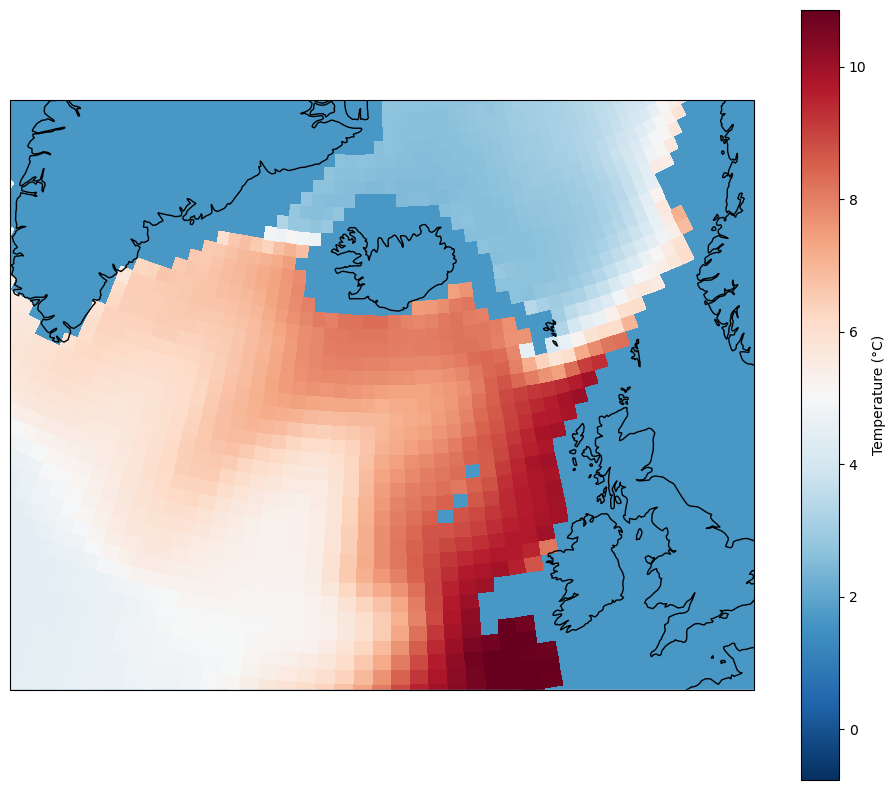

In [51]:
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.NorthPolarStereo(central_longitude=340)})

im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, cmap=cmap, norm=norm, shading='auto', transform=ccrs.PlateCarree())
ax.coastlines()
ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Temperature (°C)')

plt.show()

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem


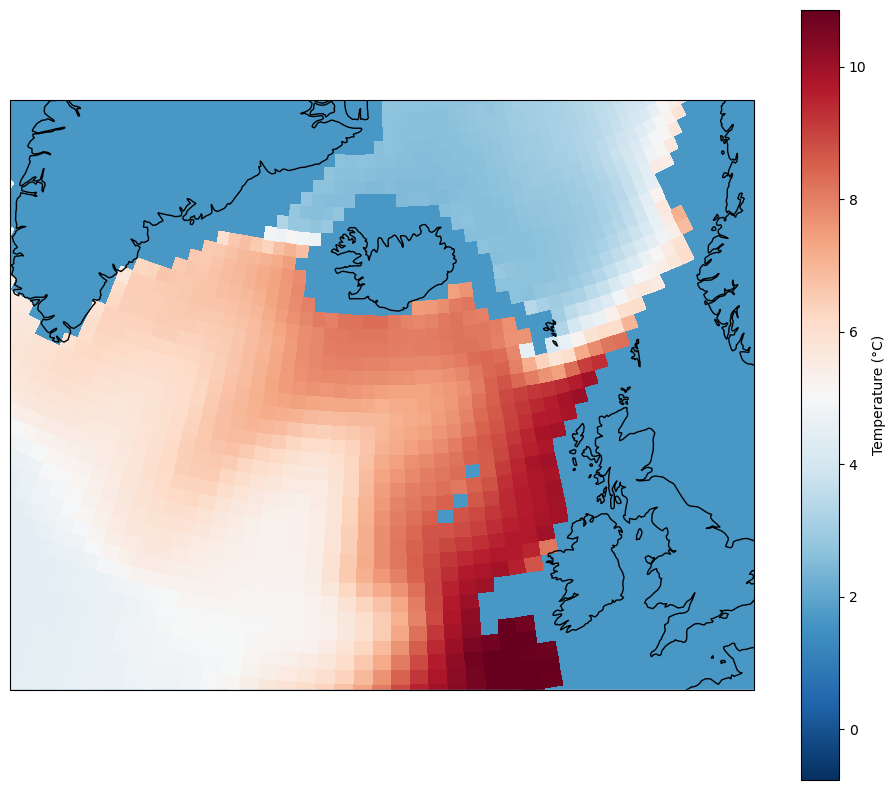

In [52]:
temp_800m = temp_800m.where(temp_800m != 2, np.nan)  
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.NorthPolarStereo(central_longitude=340)})

im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, cmap=cmap, norm=norm, shading='auto', transform=ccrs.PlateCarree())
ax.coastlines()
ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Temperature (°C)')

plt.show()

Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name cmip6: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
/Users/jaimepalter/opt/anaconda3/envs/workenv/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:301: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


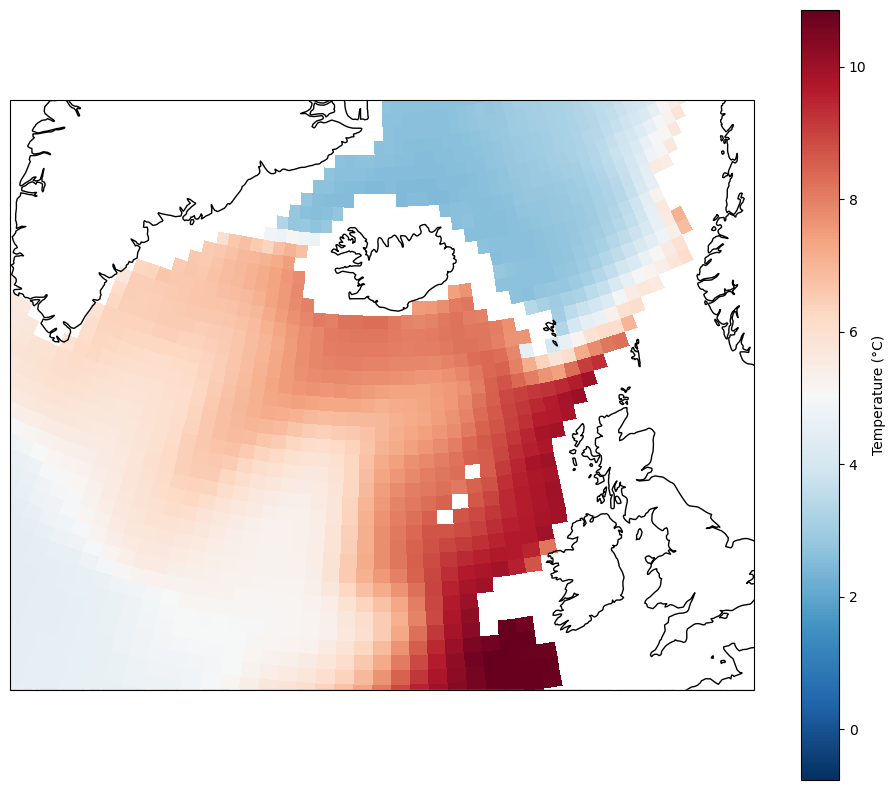

In [56]:
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.NorthPolarStereo(central_longitude=340)})

cmap.set_bad('white')  # or 'lightgray', 'none', etc.

im = ax.pcolormesh(lon_2d, lat_2d, temp_800m, 
                   cmap=cmap, norm=norm, shading='auto',
                   transform=ccrs.PlateCarree())
ax.coastlines()
ax.set_extent([320, 360, 50, 70], crs=ccrs.PlateCarree())

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Temperature (°C)')

plt.show()
